# CSC 4110 Machine Learning: task notebook


| Field | Fill in |
|---|---|
| Task | 9.2 Responsible AI and Model Card |
| Owner (name) | Group G04 — All Five Members |
| Registration number | Group task — individual contributions recorded |
| Group | G04 |
| Dataset | Credit Risk Dataset |
| Date started | 26 November 2026 |

**Rules**
- Save this file in your group folder as `G<No>_U<task>_<short name>.ipynb`, exactly as shown under **Save as** in your group's paper, e.g. `G01_U2.1_cleaning.ipynb`.
- One Markdown heading per part, then its code cells. Comment every code cell.
- Use the exact variable and file names in **Graded evidence** of your task, and `random_state=42` everywhere.
- Reviewers add a cell headed **Review by <Name>** in the Reviews section. They never edit the owner's cells.

In [ ]:
# Setup: set your group and task, connect Google Drive, and work inside the group folder
GROUP = "G04"        # your group, two digits
UNIT = "9.2"         # your task number: 2.1, 2.2, 3.1, 3.2, 4, 5, 6, 7, 8, 9.1, 9.2 or 9.3
RANDOM_STATE = 42    # use this everywhere so the grader gets the same numbers

import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted here:", e)   # normal when the grader runs this notebook

BASE = f"/content/drive/MyDrive/CSC4110_{GROUP}"
for sub in ["data", "notebooks", "models", "outputs", "app", "report", "tests"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
os.chdir(BASE)   # every path below is relative to the group folder
print("Working in", os.getcwd())

Mounted at /content/drive
Working in /content/drive/.shortcut-targets-by-id/1Hfur0Lf8z0gktOkV4oQdkhdGubaALOUm/CSC4110_G04


In [ ]:
# Libraries used in most tasks, and a helper that saves every chart to outputs/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def save_fig(name):
    """Save the current chart as outputs/<name>.png, then show it."""
    path = f"outputs/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    print("Saved", path)
    plt.show()


## Task 9.2(a): Fairness Evaluation

This section evaluates whether the loan-default model identifies actual defaulters at different rates across home-ownership and age groups.

The analysis uses held-out test records and the trained Group G04 Random Forest pipeline.


In [ ]:

# Task 9.2(a): Load the trained model and dataset

import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

# Load the group's cleaned dataset
df = pd.read_csv("data/clean_credit.csv")

# Load Peter's trained Random Forest pipeline
model = joblib.load("models/G04_model.joblib")

# Use the exact model input columns
feature_columns = [
    "person_age",
    "person_income",
    "person_home_ownership",
    "person_emp_length",
    "loan_intent",
    "loan_grade",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_default_on_file",
    "cb_person_cred_hist_length"
]

X = df[feature_columns].copy()
y = df["loan_status"].astype(int)

# Reproduce the model's previous-default encoding
X["cb_person_default_on_file"] = (
    X["cb_person_default_on_file"]
    .astype(str)
    .str.strip()
    .str.upper()
    .replace({"0": "N", "1": "Y"})
)

# Reproduce the Task 9.1 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Dataset shape:", df.shape)
print("Testing records:", len(X_test))
print("Model loaded:", hasattr(model, "predict_proba"))

print("\nResponsible AI dataset prepared successfully!")


Dataset shape: (32409, 25)
Testing records: 6482
Model loaded: True

Responsible AI dataset prepared successfully!


FAIRNESS EVALUATION RESULTS


,Group Type,Group,Test Rows,Actual Defaults,Detected Defaults,Recall
0,Home ownership,MORTGAGE,2651,343,190,0.5539
1,Home ownership,OTHER,23,5,4,0.8000
2,Home ownership,OWN,533,42,40,0.9524
3,Home ownership,RENT,3275,1028,874,0.8502
4,Age band,Under 25,2380,542,438,0.8081
5,Age band,25-34,3238,710,536,0.7549
6,Age band,35-44,712,138,111,0.8043
7,Age band,45+,152,28,23,0.8214


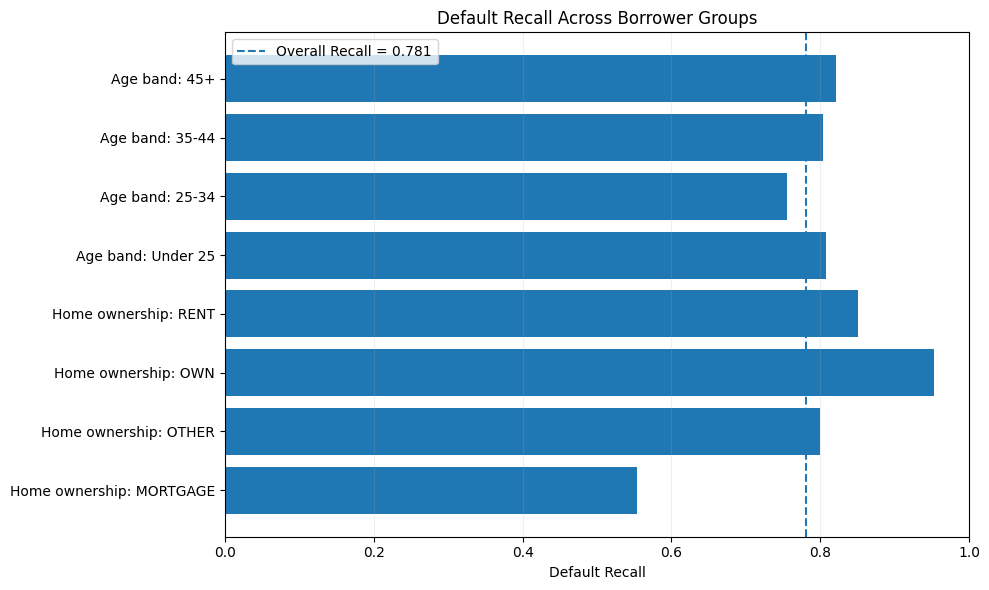

Saved: outputs/fairness.csv
Saved: outputs/fairness.png
Fairness evaluation completed!


In [ ]:

# Task 9.2(a): Compare default recall across borrower groups

# Use the app's provisional referral threshold
threshold = 0.30

# Calculate probabilities and predictions
probabilities = model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= threshold).astype(int)

# Prepare fairness data
fairness_data = X_test[
    ["person_home_ownership", "person_age"]
].copy()

fairness_data["actual_default"] = y_test
fairness_data["predicted_default"] = predictions

# Create age bands
fairness_data["age_band"] = pd.cut(
    fairness_data["person_age"],
    bins=[0, 24, 34, 44, np.inf],
    labels=["Under 25", "25-34", "35-44", "45+"]
)

# Calculate recall and group sizes
rows = []

for group_type, column in [
    ("Home ownership", "person_home_ownership"),
    ("Age band", "age_band")
]:

    for group_name, group in fairness_data.groupby(
        column,
        observed=True
    ):

        actual_defaults = int(
            (group["actual_default"] == 1).sum()
        )

        detected_defaults = int(
            (
                (group["actual_default"] == 1)
                & (group["predicted_default"] == 1)
            ).sum()
        )

        recall = (
            detected_defaults / actual_defaults
            if actual_defaults > 0 else np.nan
        )

        rows.append({
            "Group Type": group_type,
            "Group": str(group_name),
            "Test Rows": len(group),
            "Actual Defaults": actual_defaults,
            "Detected Defaults": detected_defaults,
            "Recall": recall
        })

# Store the lecturer's required variable
fairness_table = pd.DataFrame(rows)

print("FAIRNESS EVALUATION RESULTS")
display(fairness_table.round(4))

# Save the required CSV
os.makedirs("outputs", exist_ok=True)

fairness_table.to_csv(
    "outputs/fairness.csv",
    index=False
)

# Calculate the overall default recall
overall_recall = (
    ((y_test == 1) & (predictions == 1)).sum()
    / (y_test == 1).sum()
)

# Plot default recall by borrower group
plot_data = fairness_table.dropna(
    subset=["Recall"]
).copy()

plot_data["Label"] = (
    plot_data["Group Type"]
    + ": "
    + plot_data["Group"]
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Label"],
    plot_data["Recall"]
)

plt.axvline(
    overall_recall,
    linestyle="--",
    label=f"Overall Recall = {overall_recall:.3f}"
)

plt.title("Default Recall Across Borrower Groups")
plt.xlabel("Default Recall")
plt.xlim(0, 1)
plt.legend()
plt.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.savefig("outputs/fairness.png", dpi=150)
plt.show()

print("Saved: outputs/fairness.csv")
print("Saved: outputs/fairness.png")
print("Fairness evaluation completed!")



## Task 9.2(b): Identifier and Data Leakage Check

This section checks whether the classification model uses potential personal identifiers or features that could leak information about the target.

I also verify that loan_grade is excluded from the interest-rate regression features because loan grade is derived from the interest rate.


In [ ]:

# Task 9.2(b): Check model features and potential leakage

import numpy as np
import pandas as pd

# Get the original input features used by the saved model
feature_names = list(model.feature_names_in_)

print("MODEL INPUT FEATURES")
for feature in feature_names:
    print(feature)

# Check for potential personal identifier names
identifier_terms = ["id", "name", "phone", "email"]

# Store the required flagged variable
flagged = [
    feature for feature in feature_names
    if any(term in feature.lower() for term in identifier_terms)
]

print("\nPOTENTIAL IDENTIFIER FEATURES")
print(flagged if flagged else "None found")

# Calculate correlations for numerical model inputs
numeric_features = [
    col for col in feature_names
    if col in df.select_dtypes(include="number").columns
]

correlations = (
    df[numeric_features]
    .corrwith(df["loan_status"])
    .abs()
    .sort_values(ascending=False)
)

print("\nABSOLUTE CORRELATIONS WITH LOAN STATUS")
print(correlations.round(4))

# Flag unusually high target correlations
high_corr_features = correlations[
    correlations > 0.95
]

print("\nFEATURES ABOVE 0.95 CORRELATION")
print(
    high_corr_features.round(4)
    if not high_corr_features.empty
    else "None found"
)

# Check regression features separately
regression_features = (
    df.select_dtypes(include="number")
    .drop(
        columns=[
            "loan_int_rate",
            "loan_grade",
            "loan_status",
            "rate_imputed"
        ],
        errors="ignore"
    )
    .columns.tolist()
)

print("\nLOAN GRADE LEAKAGE CHECK")
print(
    "loan_grade excluded from regression:",
    "loan_grade" not in regression_features
)

assert "loan_grade" not in regression_features

print("\nIdentifier and leakage checks completed!")


MODEL INPUT FEATURES
person_age
person_income
person_home_ownership
person_emp_length
loan_intent
loan_grade
loan_amnt
loan_percent_income
cb_person_default_on_file
cb_person_cred_hist_length

POTENTIAL IDENTIFIER FEATURES
None found

ABSOLUTE CORRELATIONS WITH LOAN STATUS
loan_percent_income           0.3796
loan_grade                    0.3734
person_income                 0.2461
cb_person_default_on_file     0.1792
loan_amnt                     0.1056
person_emp_length             0.0860
person_age                    0.0218
cb_person_cred_hist_length    0.0164
dtype: float64

FEATURES ABOVE 0.95 CORRELATION
None found

LOAN GRADE LEAKAGE CHECK
loan_grade excluded from regression: True

Identifier and leakage checks completed!



## Task 9.2(c): Responsible AI Model Card

This section documents the purpose, intended users, model performance, fairness findings, limitations and release requirements of the Mulika SACCO loan-default prediction model.

The model card will be saved as report/model_card.md and completed collaboratively by all five members of Group G04.


In [ ]:

# Task 9.2(c): Calculate model performance at both thresholds

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Obtain default probabilities
probabilities = model.predict_proba(X_test)[:, 1]

# Store performance results
model_card_scores = {}

for t in [0.5, 0.3]:

    predicted = (probabilities >= t).astype(int)

    model_card_scores[t] = {
        "Accuracy": accuracy_score(y_test, predicted),
        "Precision": precision_score(
            y_test, predicted, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predicted, zero_division=0
        ),
        "F1": f1_score(
            y_test, predicted, zero_division=0
        )
    }

print("MODEL CARD PERFORMANCE RESULTS")
display(pd.DataFrame(model_card_scores).T.round(4))


MODEL CARD PERFORMANCE RESULTS


,Accuracy,Precision,Recall,F1
0.5,0.9364,0.9736,0.7292,0.8339
0.3,0.9202,0.8426,0.7814,0.8108


In [ ]:

# Task 9.2(c): Create the model card draft

from pathlib import Path

# Retrieve model performance
scores_05 = model_card_scores[0.5]
scores_03 = model_card_scores[0.3]

# Calculate the largest home-ownership recall gap
home_groups = fairness_table[
    fairness_table["Group Type"] == "Home ownership"
]

home_gap = (
    home_groups["Recall"].max()
    - home_groups["Recall"].min()
)

# Build the fairness results table
fairness_lines = [
    "| Group Type | Group | Test Rows | Actual Defaults | Recall |",
    "|---|---|---:|---:|---:|"
]

for _, row in fairness_table.iterrows():
    fairness_lines.append(
        f"| {row['Group Type']} | {row['Group']} | "
        f"{int(row['Test Rows'])} | "
        f"{int(row['Actual Defaults'])} | "
        f"{row['Recall']:.2%} |"
    )

fairness_markdown = "\n".join(fairness_lines)

# Build the model card
model_card = f"""# Mulika SACCO — Model Card

## Model Purpose

The model estimates the probability that a loan applicant
will default. It supports loan officers during application
review and must not automatically approve or reject loans.

## Intended Users

The intended users are trained SACCO loan officers and
authorised staff involved in reviewing loan applications.

## Data Source and Licence

Dataset: Credit Risk Dataset

Original file: data/credit_risk_dataset.csv

Cleaned file: data/clean_credit.csv

Dataset licence: TO BE VERIFIED from the original source
before final submission or public deployment.

## Model and Features Used

Algorithm: Random Forest Classifier

Model file: models/G04_model.joblib

The model includes numerical and categorical preprocessing.

Input features:

{chr(10).join("- " + f for f in feature_columns)}

The availability of internally assigned loan_grade must be
verified before deployment.

## Performance on Test Data

Held-out test records: {len(X_test)}

At threshold 0.5:

- Accuracy: {scores_05['Accuracy']:.4f}
- Precision: {scores_05['Precision']:.4f}
- Recall: {scores_05['Recall']:.4f}
- F1-score: {scores_05['F1']:.4f}

At provisional referral threshold 0.3:

- Accuracy: {scores_03['Accuracy']:.4f}
- Precision: {scores_03['Precision']:.4f}
- Recall: {scores_03['Recall']:.4f}
- F1-score: {scores_03['F1']:.4f}

The referral threshold requires independent validation
before operational use.

## Fairness Check Results

The following table compares recall for actual defaulters
across home-ownership and age groups.

{fairness_markdown}

Largest observed home-ownership recall gap:
{home_gap * 100:.2f} percentage points.

The largest observed difference is between OWN and
MORTGAGE borrowers.

Some groups have few actual defaults. Their recall
estimates may therefore be unreliable.

These differences require investigation and do not alone
establish discrimination.

## Identifier and Leakage Checks

No input column names matched the screened personal
identifier terms.

No checked numeric input feature had an absolute
correlation greater than 0.95 with loan_status.

loan_grade was excluded from the reconstructed
interest-rate regression feature set.

These checks do not rule out every source of leakage.

## Limitations

- The dataset may not represent actual SACCO applicants.
- Predictions may be less reliable for unusual applicants.
- The model may perform differently across borrower groups.
- The model does not explain every reason for a default.
- The provisional threshold was not selected specifically
  for the deployed Random Forest using independent
  validation data.
- Historical patterns may reflect existing financial
  inequalities.

## Who Should Not Use the Model

Applicants must not use this model to determine whether
they qualify for a loan.

The model must not be used to automatically deny loans.

It must not be used for real lending decisions without
appropriate validation, oversight and approval.

## Testing Before Release

Test data: the held-out 20% classification test split.

Proposed release targets, subject to group approval:

- Default recall of at least 0.80.
- F1-score of at least 0.75 at the selected threshold.
- Investigate substantial recall gaps between borrower
  groups before operational release.

These are proposed targets, not claims that the model
already meets them.

Before release, select and validate the decision threshold
without repeatedly tuning on the held-out test set.

The first pilot should involve a designated loan officer
and supervised demonstration using fictional applicants.

If the model fails the release checks, it should remain
a coursework demonstration.

## Human Oversight

The model supports but does not replace the loan officer.

Every application must receive appropriate human review.

A refused applicant must be given a clear reason and an
appropriate opportunity to seek clarification.

## Group Contributions

Each of the five members must review and contribute to
this model card and record their own GitHub commit.

The group must verify the dataset licence, threshold,
fairness findings and release requirements before approval.
"""

# Save the document
Path("report").mkdir(exist_ok=True)

card_path = Path("report/model_card.md")
card_path.write_text(model_card, encoding="utf-8")

print("MODEL CARD CREATED SUCCESSFULLY")
print("File:", card_path)
print("File exists:", card_path.is_file())
print("File size:", card_path.stat().st_size, "bytes")


MODEL CARD CREATED SUCCESSFULLY
File: report/model_card.md
File exists: True
File size: 4563 bytes


## Load the data

- Task 2.1 loads the original Kaggle file.
- Task 2.2 loads `data/stage1_<dataset>.csv`.
- Every other task loads `data/clean_<dataset>.csv`.

In [ ]:
# Load the data for this task (change the file name to your group's file)
DATA_FILE = "data/clean_<dataset>.csv"
df = pd.read_csv(DATA_FILE)
print(df.shape)
df.head()

## Part a) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [ ]:
# a1. <what this cell does>


## Part b) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [ ]:
# b1. <what this cell does>


## Part c) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [ ]:
# c1. <what this cell does>


## Written answer

Write the answer the task asks for. Quote your own numbers, for example "test RMSE fell from 6.2 to 4.8".

## Reviews

### Review by <Name>
A check, an improvement or a question.

## Evidence checklist (tick before you submit)

- [ ] Runtime → Restart session and run all: no errors
- [ ] The basic check below shows no missing names or files
- [ ] The written answer is complete and quotes my numbers
- [ ] The self-check cell from Moodle passes
- [ ] File → Save, and File → Save a copy in GitHub

In [ ]:
# Basic check: are the required variables and files there? (names and files only;
# the self-check cell on Moodle also tests the values)
import glob
REQUIRED = {
    "2.1": (["df_raw", "df_stage1", "outlier_col", "lower", "upper"], ["data/stage1_*.csv"]),
    "2.2": (["df_clean", "X_train", "X_test", "y_train", "y_test", "scaler"],
            ["data/clean_*.csv", "outputs/hist_target.png", "outputs/box_feature.png",
             "outputs/bar_class.png", "outputs/scatter_best.png", "outputs/corr_heatmap.png"]),
    "3.1": (["lr_simple", "lr_multi", "metrics_multi", "b0_gd", "b1_gd", "cost_history"],
            ["outputs/simple_fit.png", "outputs/actual_vs_pred.png", "outputs/gd_cost.png"]),
    "3.2": (["poly_results", "ridge_results", "lasso_results", "results_reg"],
            ["outputs/under_over_fit.png", "outputs/regression_comparison.png"]),
    "4":   (["y_train", "y_test", "log_reg", "cm", "results_clf"], ["outputs/confusion_matrix.png"]),
    "5":   (["pipe", "cv_scores", "grid", "test_score", "threshold_results"],
            ["outputs/learning_curve.png", "outputs/validation_curve.png"]),
    "6":   (["tree3", "ig_root", "depth_results", "results_trees", "importances"],
            ["outputs/tree_depth3.png", "outputs/depth_curve.png", "outputs/feature_importance.png"]),
    "7":   (["inertias", "sil_scores", "best_k", "pca", "dbscan_labels", "Q", "success_rates"],
            ["outputs/elbow.png", "outputs/pca_clusters.png", "outputs/success_rate.png"]),
    "8":   (["w_and", "b_and", "mlp_results", "best_mlp", "activation_results", "mlp_reg_rmse"], ["outputs/loss_curve.png"]),
    "9.1": (["final_pipe"], ["models/*_model.joblib", "app/app.py", "app/requirements.txt",
                             "outputs/app_screenshot.png"]),
    "9.2": (["fairness_table", "flagged"], ["outputs/fairness.csv", "outputs/fairness.png",
                                            "report/model_card.md"]),
    "9.3": ([], ["tests/smoke_test.py", "README.md"]),
}
names, files = REQUIRED[UNIT]
missing_names = [n for n in names if n not in globals()]
missing_files = [f for f in files if not glob.glob(f)]
print(f"Task {UNIT}")
print("Missing variables:", missing_names or "none")
print("Missing files:", missing_files or "none")
print("PASS" if not (missing_names or missing_files) else "FIX the items above before you submit")

Task 9.2
Missing variables: none
Missing files: none
PASS


## Self-check

Paste the self-check cell for your task from its Moodle assignment below, then run it.

In [ ]:
# Paste the self-check cell from Moodle here
